# Progetto di Classificazione di Forme Geometriche da Sequenze di Punti

## Obiettivo del progetto

Lo scopo di questo progetto è sviluppare un sistema automatico in grado di riconoscere forme geometriche semplici - ellissi, rettangoli, segmenti e coppie di segmenti che si incrociano in modo ortogonale, a croce - a partire da sequenze di punti che ne rappresentano il contorno.

## Dataset
Il dataset viene calcolato in modo sintetico per mezzo della funzione _genera_campioni_, che determina una sequenza di punti per ogni forma, aggiungendo un eventuale rumore gaussiano.
Si consideri inizialmente un dataset composto da **4000 forme** (1000 per tipo) ognuna descritta da 100 punti, ordinati secondo l'ordine di generazione dell'algoritmo utilizzato, con associato il relativo target, sotto forma di un intero tra 0 e 3, associato a una label per la forma dalla lista labels. 


200 valori rappresenta un campione etichettato costituito da una sequenza di numeri in vergola mobile $x_1\ y_1\ x_2\ y_2\ \ldots x_{100}\ y_{100}$ che rappresentano le $200$ coordinate dei $100$  punti che descrivono il perimetro della forma, seguita da una etichetta testuale (ellisse, rettangolo, segmento, croce) che indica la forma rappresentata.

## Compiti dello studente

Lo studente dovrà progettare un **classificatore automatico** in grado di riconoscere correttamente la forma rappresentata da ciascuna sequenza. Il progetto richiede di affrontare i seguenti step:

### 1. Rappresentazione e feature engineering
Definire una rappresentazione vettoriale delle forme implementando la funzione _ottieni_features_. Nel codice, viene fornita una implementazione di tale funzione corrispondente ad una banale rappresentazione in cui l'insieme di punti $(x_1,y_1), \ldots, (x_n, y_n)$ è rappresentato da un vettore $x_1,y_1, \ldots,x_n, y_n$. Si valuti l'utilizzo di rappresetazioni diverse sia utilizzando metodi algoritmici (feature selection, feature extraction) che definendo nuove features (es. distanza dal centroide, perimetro e distanza tra punti estremi, etc.).

### 2. Costruzione e valutazione di classificatori

- Utilizzare le caratteristiche estratte per addestrare e confrontare un insieme di classificatori, valutando anche il valore ottimo (o sufficientemente buono) di iperparametri definiti per il classificatore considerato (model selection), utilizzano un validation set o la cross-validation
- Valutare le prestazioni dei vari modelli su un test set anch'esso sintetico, derivato dal dataset calcolato mediante splitting o anche prodotto utilizzando il medesimo algoritmo.
- Esaminare e confrontare le prestazioni ottenute sul training e sul test set e controllare l'eventaule overfitting

### 3. Test di robustezza
Analizzare l'effetto sulle prestazioni ottenute dai vari modelli, e su quelle del miglior classificatore di
- Quantità di forme disponibili come esempio
- Numero di punti che descrivono la singola forma
- Quantità di rumore gaussiano
Analizzare inoltre la differenza di prestazioni al variare del dataset considerato, prodotto comunque secondo il medesimo algoritmo.

### 4. Classificazione binaria
Considerare il problema di classificazione binaria derivato considerando la classe delle forme con area nulla (segmento, croce) vs. la classe di quelle ad area positiva (ellisse, rettangolo), unendo quindi da un lato le classi 0 e 1 e dall'altro le classi 2,3. Analizzare le prestazioni ottenute sul problema secondo le indicazioni precedenti.

In [557]:
import matplotlib.pyplot as plt
import numpy as np
import csv

def to_stringa(punti, forma):
    return ";".join(f"{x:.3f}:{y:.3f}" for x, y in punti)+','+forma

def genera_segmento(x0, y0, theta, l, n_punti=50, rumore_std = 0.01):
    """
    Genera un segmento rettilineo con n_punti, tra due estremi calcolati a partire da un punto centrale (x0, y0),
    una lunghezza totale l e un angolo theta rispetto all'asse x. I punti sono distribuiti uniformemente lungo il segmento,
    con l'aggiunta opzionale di rumore gaussiano.

    Args:
        x0 (float): coordinata x del punto centrale del segmento
        y0 (float): coordinata y del punto centrale del segmento
        theta (float): angolo del segmento rispetto all'asse x (in radianti)
        l (float): metà lunghezza del segmento (il segmento totale sarà lungo 2*l)
        n_punti (int): numero di punti da generare lungo il segmento
        rumore_std (float): deviazione standard del rumore gaussiano da aggiungere ai punti

    Returns:
        np.ndarray: array di shape (n_punti, 2) contenente le coordinate dei punti generati
    """
    # Calcola le coordinate dei due estremi del segmento
    x1 = x0 + l * np.cos(theta)
    y1 = y0 + l * np.sin(theta)
    x2 = x0 - l * np.cos(theta)
    y2 = y0 - l * np.sin(theta)
    # Interpolazione lineare tra i due estremi per ottenere i punti
    t = np.linspace(0, 1, n_punti)
    x = x1 + t * (x2 - x1)
    y = y1 + t * (y2 - y1)
    # Aggiunta di rumore gaussiano alle coordinate
    x += np.random.normal(0, rumore_std, size=n_punti)
    y += np.random.normal(0, rumore_std, size=n_punti)
    # Restituisce un array Nx2 con i punti generati
    return np.stack([x, y], axis=1)  # shape: (n_punti, 2)

def genera_croce(x0, y0, theta, l, n_punti=50, rumore_std = 0.01):
    """
    Genera una croce composta da due segmenti ortogonali che si intersecano nel punto (x0, y0).
    Ogni segmento è centrato in (x0, y0), ha lunghezza totale 2*l e angolo theta (il secondo segmento è ruotato di 90° rispetto al primo).
    I punti sono distribuiti uniformemente lungo i segmenti, con aggiunta opzionale di rumore gaussiano.

    Args:
        x0 (float): coordinata x del centro della croce
        y0 (float): coordinata y del centro della croce
        theta (float): angolo del primo segmento rispetto all'asse x (in radianti)
        l (float): metà lunghezza di ciascun segmento (ogni segmento è lungo 2*l)
        n_punti (int): numero totale di punti da generare (divisi equamente tra i due segmenti)
        rumore_std (float): deviazione standard del rumore gaussiano da aggiungere ai punti

    Returns:
        np.ndarray: array di shape (n_punti, 2) contenente le coordinate dei punti generati
    """
    # Primo segmento (angolo theta)
    x1 = x0 + l * np.cos(theta)
    y1 = y0 + l * np.sin(theta)
    x2 = x0 - l * np.cos(theta)
    y2 = y0 - l * np.sin(theta)
    t = np.linspace(0, 1, n_punti//2)
    x = x1 + t * (x2 - x1)
    y = y1 + t * (y2 - y1)
    x += np.random.normal(0, rumore_std, size=n_punti//2)
    y += np.random.normal(0, rumore_std, size=n_punti//2)

    # Secondo segmento (angolo theta + 90°)
    x1 = x0 - l * np.sin(theta)
    y1 = y0 + l * np.cos(theta)
    x2 = x0 + l * np.sin(theta)
    y2 = y0 - l * np.cos(theta)
    t = np.linspace(0, 1, n_punti//2)
    xx = x1 + t * (x2 - x1)
    yy = y1 + t * (y2 - y1)
    xx += np.random.normal(0, rumore_std, size=n_punti//2)
    yy += np.random.normal(0, rumore_std, size=n_punti//2)

    # Unisce i punti dei due segmenti
    x = np.concatenate([x, xx])
    y = np.concatenate([y, yy])

    return np.stack([x, y], axis=1)  # shape: (n_punti, 2)



def genera_ellisse(a=1.0, b=0.5, centro=(0, 0), angolo=0.0, n_punti=100, rumore_std=0.0):
    """
    Genera punti su un'ellisse centrata in `centro`, con semiassi `a` e `b`,
    ruotata di `angolo` radianti, e opzionalmente con rumore gaussiano.

    Parametri:
    - a (float): semiasse maggiore
    - b (float): semiasse minore
    - centro (tuple): coordinate del centro (x0, y0)
    - angolo (float): rotazione in radianti (es. np.pi/4 per 45°)
    - n_punti (int): numero di punti da generare
    - rumore_std (float): deviazione standard del rumore gaussiano da aggiungere

    Ritorna:
    - array Nx2 con i punti [x, y]
    """
    
    t = np.linspace(0, 2 * np.pi, n_punti)
    x = a * np.cos(t)
    y = b * np.sin(t)

    # Rotazione
    x_rot = x * np.cos(angolo) - y * np.sin(angolo)
    y_rot = x * np.sin(angolo) + y * np.cos(angolo)

    # Traslazione
    x_finale = x_rot + centro[0]
    y_finale = y_rot + centro[1]

    # Rumore
    x_finale += np.random.normal(0, rumore_std, size=n_punti)
    y_finale += np.random.normal(0, rumore_std, size=n_punti)

    return np.stack([x_finale, y_finale], axis=1)


def genera_rettangolo(larghezza=1.0, altezza=0.5, centro=(0, 0), angolo=0.0,
            rumore_std=0.0, n_punti=100):
    """
    Genera punti distribuiti lungo i 4 lati di un rettangolo ruotato e centrato,
    in modo proporzionale alla lunghezza dei lati.

    Args:
        larghezza (float): larghezza del rettangolo
        altezza (float): altezza del rettangolo
        centro (tuple): centro (x, y)
        angolo (float): rotazione in radianti
        rumore_std (float): rumore gaussiano (std dev)
        n_punti (int): numero totale di punti da generare

    Returns:
        np.ndarray: array (n_punti, 2) con i punti lungo i lati
    """
    if n_punti < 4:
        raise ValueError("n_punti deve essere almeno 4")

    # Vertici base
    w, h = larghezza / 2, altezza / 2
    vertici = np.array([
        [-w, -h],
        [ w, -h],
        [ w,  h],
        [-w,  h]
    ])

    # Lati e lunghezze
    lati = [(vertici[(i+1) % 4] - vertici[i]) for i in range(4)]
    lunghezze = np.array([np.linalg.norm(l) for l in lati])
    proporzioni = lunghezze / lunghezze.sum()

    # Distribuzione dei punti
    n_per_lato = np.floor(proporzioni * n_punti).astype(int)
    restante = n_punti - n_per_lato.sum()
    for i in range(restante):
        n_per_lato[i % 4] += 1

    # Generazione dei punti
    punti = []
    for i, n in enumerate(n_per_lato):
        start = vertici[i]
        end = vertici[(i + 1) % 4]
        t_values = np.linspace(0, 1, n, endpoint=False)
        lato = np.outer(1 - t_values, start) + np.outer(t_values, end)
        punti.append(lato)
    punti = np.vstack(punti)

    # Rotazione, traslazione e rumore
    R = np.array([
        [np.cos(angolo), -np.sin(angolo)],
        [np.sin(angolo),  np.cos(angolo)]
    ])
    punti = punti @ R.T
    punti += np.array(centro)
    punti += np.random.normal(0, rumore_std, punti.shape)

    return punti

Genera istanze sintetiche

In [558]:
def genera_campioni(n_shapes = 100, n_punti = 50, rumore_std_bound=0.2):
    """
    Genera un dataset sintetico di forme geometriche (ellissi, rettangoli, segmenti e croci)
    rappresentate come sequenze di punti 2D, con etichette numeriche.

    Parametri:
        n_shapes (int): Numero di istanze da generare per ciascuna classe di forma.
        n_punti (int): Numero di punti che descrivono ciascuna forma.
        rumore_std_bound (float): Valore massimo della deviazione standard del rumore gaussiano
                                  aggiunto alle coordinate dei punti.

    Restituisce:
        X (np.ndarray): Array di shape (4*n_shapes, n_punti, 2) contenente i punti delle forme.
        y (np.ndarray): Array di shape (4*n_shapes,) contenente le etichette numeriche delle forme:
                        0=ellisse, 1=rettangolo, 2=segmento, 3=croce.

    Ogni forma viene generata con parametri casuali (dimensioni, posizione, rotazione, rumore).
    """

    X, y = [], []  # Liste per memorizzare i campioni e le etichette

    # Genera ellissi
    for _ in range(n_shapes):
        a = np.random.uniform(0.5, 3.0)                  # semiasse maggiore
        b = np.random.uniform(0.3, a)                    # semiasse minore
        centro = (np.random.uniform(-5, 5), np.random.uniform(-5, 5))  # centro casuale
        angolo = np.random.uniform(0, 2 * np.pi)         # rotazione casuale
        rumore = np.random.uniform(0.0, rumore_std_bound)  # rumore casuale
        punti = genera_ellisse(a, b, centro, angolo, n_punti=n_punti, rumore_std=rumore)  # genera punti
        X.append(punti)
        y.append(0)  # 0 = ellisse

    # Genera rettangoli
    for _ in range(n_shapes):
        punti = genera_rettangolo(
            larghezza=np.random.uniform(0.5, 3.0),       # larghezza casuale
            altezza=np.random.uniform(0.5, 2.0),         # altezza casuale
            centro=(np.random.uniform(-5, 5), np.random.uniform(-5, 5)),  # centro casuale
            angolo=np.random.uniform(0, 2*np.pi),        # rotazione casuale
            rumore_std = np.random.uniform(0.0, rumore_std_bound),        # rumore casuale
            n_punti = n_punti
        )
        X.append(punti)
        y.append(1) # 1 = rettangolo

    # Genera segmenti
    for _ in range(n_shapes):
        x0, y0 = np.random.uniform(-5, 5 ), np.random.uniform(-5, 5 )  # centro casuale
        l, theta = np.random.uniform(0, 10 ), np.random.uniform(0, np.pi )  # lunghezza e angolo casuali
        punti = genera_segmento(x0, y0, l, theta, n_punti=n_punti,
                                rumore_std = np.random.uniform(0.0, rumore_std_bound))  # genera punti
        X.append(punti)
        y.append(2)
        
    # Genera croci (due segmenti ortogonali)
    for _ in range(n_shapes):
        x0, y0 = np.random.uniform(-5, 5 ), np.random.uniform(-5, 5 )  # centro casuale
        l, theta = np.random.uniform(0, 10 ), np.random.uniform(0, np.pi )  # lunghezza e angolo casuali
        punti = genera_croce(x0, y0, l, theta, n_punti=n_punti,
                                rumore_std = np.random.uniform(0.0, rumore_std_bound))  # genera punti
        X.append(punti)
        y.append(3)  # 3 = croce
        
    return np.array(X), np.array(y)  # restituisce array di campioni e etichette

In [559]:
labels = ['ellisse', 'rettangolo', 'segmento', 'croce']


In [560]:
def esporta_dataset(filename, X, y):
    """
    Esporta un dataset di forme geometriche su file.

    Ogni riga del file conterrà le coordinate appiattite di una forma,
    separate da virgole, seguite dalla label testuale corrispondente.

    Args:
        filename (str): Nome del file di output.
        X (np.ndarray): Array di forme, ciascuna rappresentata da una sequenza di punti 2D.
        y (np.ndarray): Array di etichette numeriche delle forme.

    Returns:
        None
    """
    # Apre il file in modalità scrittura
    with open(filename, "w") as f:
        # Itera su ogni coppia di campione (x) e label (l)
        for x, l in zip(X, y):
            # Appiattisce l'array x, lo converte in stringa senza parentesi quadre,
            # aggiunge la label testuale corrispondente e va a capo
            f.write(np.array2string(x.flatten(), max_line_width=np.inf)[1:-1] + ',' + labels[l] + '\n')

# Analisi esplorativa

Come prima cosa, per farsi un idea delle caratteristiche del dataset, eseguiamo un analisi esplorativa del dataset.

### Visualizza le figure geometriche

Visualizzazione esempi per tipo:


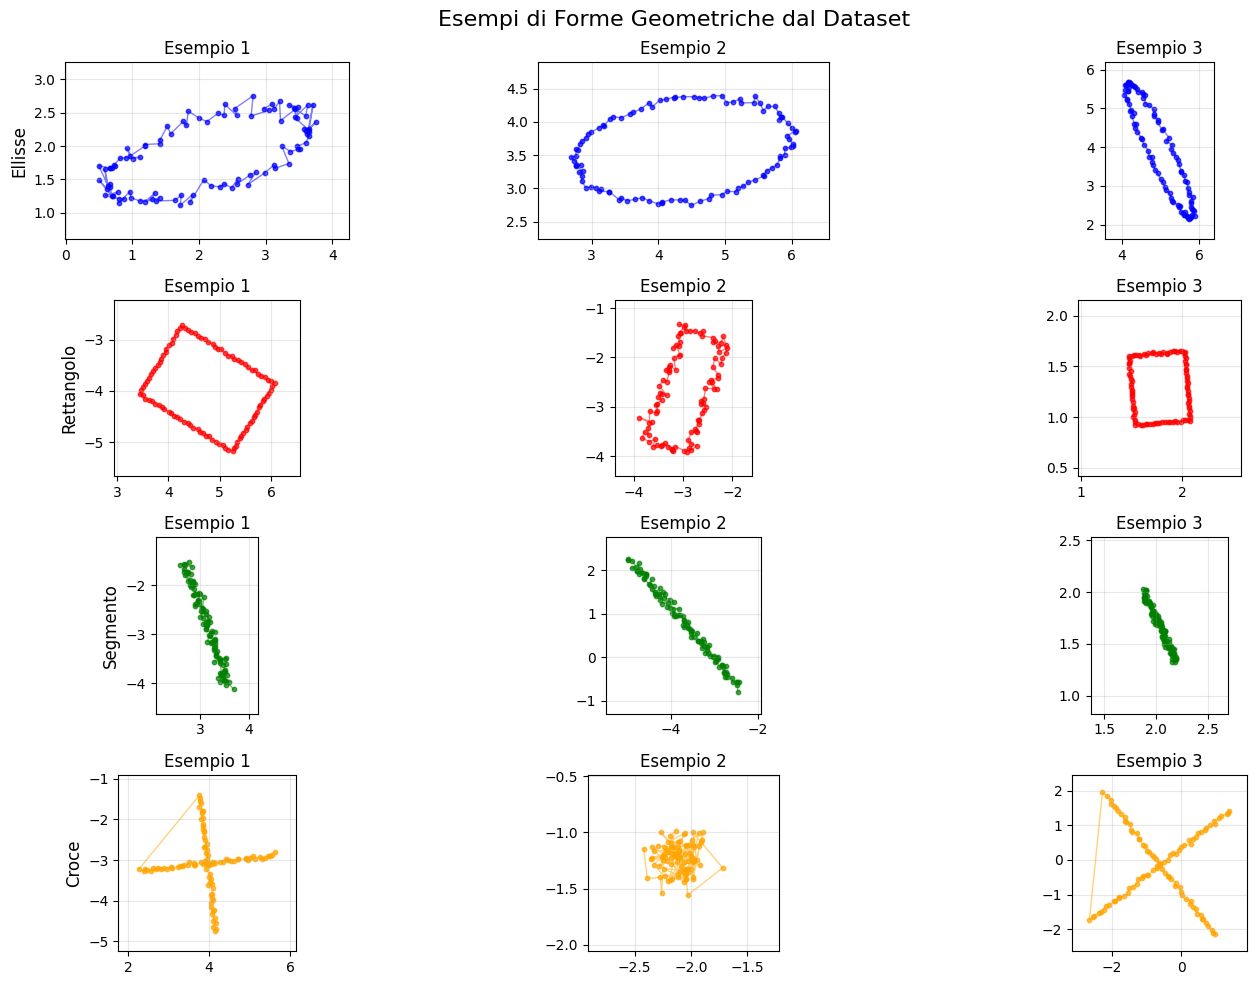


Distribuzione generale:


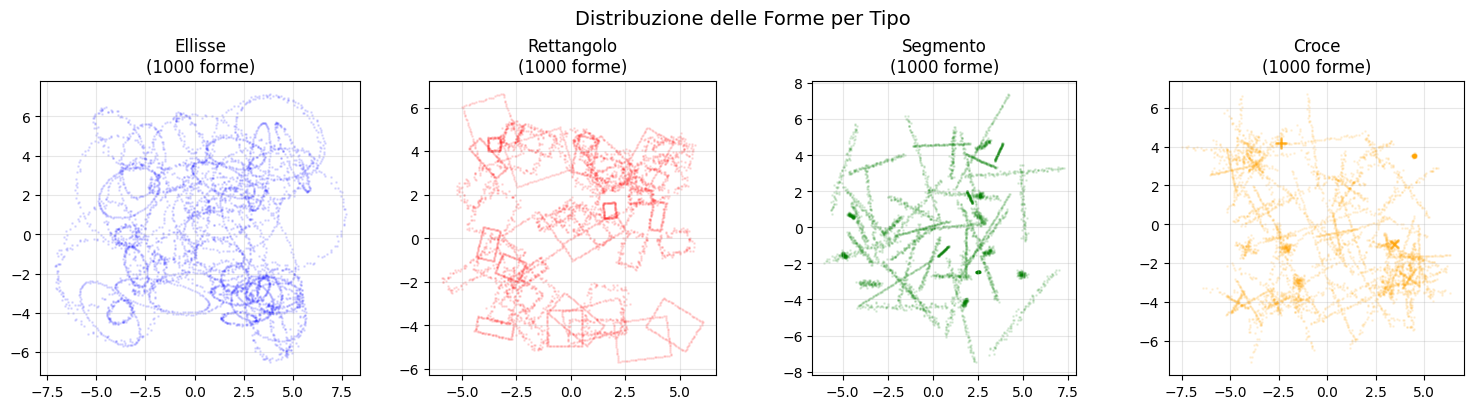

In [561]:
import matplotlib.pyplot as plt
import numpy as np

def visualizza_forme(X, y, n_per_tipo=4, figsize=(15, 10)):
    """
    Visualizza esempi di forme geometriche dal dataset.
    
    Parametri:
        X (np.ndarray): Array di forme (n_samples, n_punti, 2)
        y (np.ndarray): Array di etichette (n_samples,)
        n_per_tipo (int): Numero di esempi da mostrare per ogni tipo di forma
        figsize (tuple): Dimensione della figura
    """
    
    labels = ['ellisse', 'rettangolo', 'segmento', 'croce']
    colori = ['blue', 'red', 'green', 'orange']
    
    # Crea una griglia di subplot
    fig, axes = plt.subplots(4, n_per_tipo, figsize=figsize)
    fig.suptitle('Esempi di Forme Geometriche dal Dataset', fontsize=16)
    
    # Per ogni tipo di forma
    for tipo_forma in range(4):
        # Trova gli indici delle forme di questo tipo
        indici = np.where(y == tipo_forma)[0]
        
        # Prendi i primi n_per_tipo esempi
        esempi = indici[:n_per_tipo]
        
        for i, idx in enumerate(esempi):
            ax = axes[tipo_forma, i]
            
            # Estrai i punti della forma
            punti = X[idx]
            
            # Disegna i punti
            ax.scatter(punti[:, 0], punti[:, 1], 
                      c=colori[tipo_forma], s=10, alpha=0.7)
            
            # Collega i punti per vedere meglio la forma
            if tipo_forma in [0, 1]:  # ellisse e rettangolo: chiudi la forma
                punti_chiusi = np.vstack([punti, punti[0]])
                ax.plot(punti_chiusi[:, 0], punti_chiusi[:, 1], 
                       c=colori[tipo_forma], linewidth=1, alpha=0.5)
            else:  # segmento e croce: non chiudere
                ax.plot(punti[:, 0], punti[:, 1], 
                       c=colori[tipo_forma], linewidth=1, alpha=0.5)
            
            # Imposta titolo e formato
            if i == 0:
                ax.set_ylabel(f'{labels[tipo_forma].capitalize()}', fontsize=12)
            
            ax.set_title(f'Esempio {i+1}')
            ax.grid(True, alpha=0.3)
            ax.set_aspect('equal')
            
            # Imposta i limiti degli assi per una visualizzazione uniforme
            ax.set_xlim(punti[:, 0].min() - 0.5, punti[:, 0].max() + 0.5)
            ax.set_ylim(punti[:, 1].min() - 0.5, punti[:, 1].max() + 0.5)
    
    plt.tight_layout()
    plt.show()

def visualizza_distribuzione_forme(X, y, figsize=(15, 4)):
    """
    Visualizza la distribuzione di tutte le forme in un unico plot per tipo.
    
    Parametri:
        X (np.ndarray): Array di forme
        y (np.ndarray): Array di etichette
        figsize (tuple): Dimensione della figura
    """
    
    labels = ['ellisse', 'rettangolo', 'segmento', 'croce']
    colori = ['blue', 'red', 'green', 'orange']
    
    fig, axes = plt.subplots(1, 4, figsize=figsize)
    
    for tipo in range(4):
        ax = axes[tipo]
        
        # Trova tutte le forme di questo tipo
        indici = np.where(y == tipo)[0]
        
        # Disegna tutte le forme sovrapposte
        for idx in indici[:50]:  # Limita a 50 per non sovraccaricare
            punti = X[idx]
            ax.scatter(punti[:, 0], punti[:, 1], 
                      c=colori[tipo], s=1, alpha=0.1)
        
        ax.set_title(f'{labels[tipo].capitalize()}\n({len(indici)} forme)')
        ax.grid(True, alpha=0.3)
        ax.set_aspect('equal')
    
    plt.suptitle('Distribuzione delle Forme per Tipo', fontsize=14)
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    # Genera dataset di esempio
    X, y = genera_campioni(n_shapes=1000, n_punti=100, rumore_std_bound=0.1)
    
    # Visualizza esempi
    print("Visualizzazione esempi per tipo:")
    visualizza_forme(X, y, n_per_tipo=3)
    
    # Visualizza distribuzione
    print("\nDistribuzione generale:")
    visualizza_distribuzione_forme(X, y)

Procediamo ora a vedere la correlazione tra alcune caratteristiche geometriche e le figure geometriche.

/var/folders/7f/rhx7fk8n4klg6k77kffc697w0000gn/T/ipykernel_37878/1601197062.py:68: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax1.boxplot(varianze_per_classe, labels=labels_nomi, patch_artist=True)


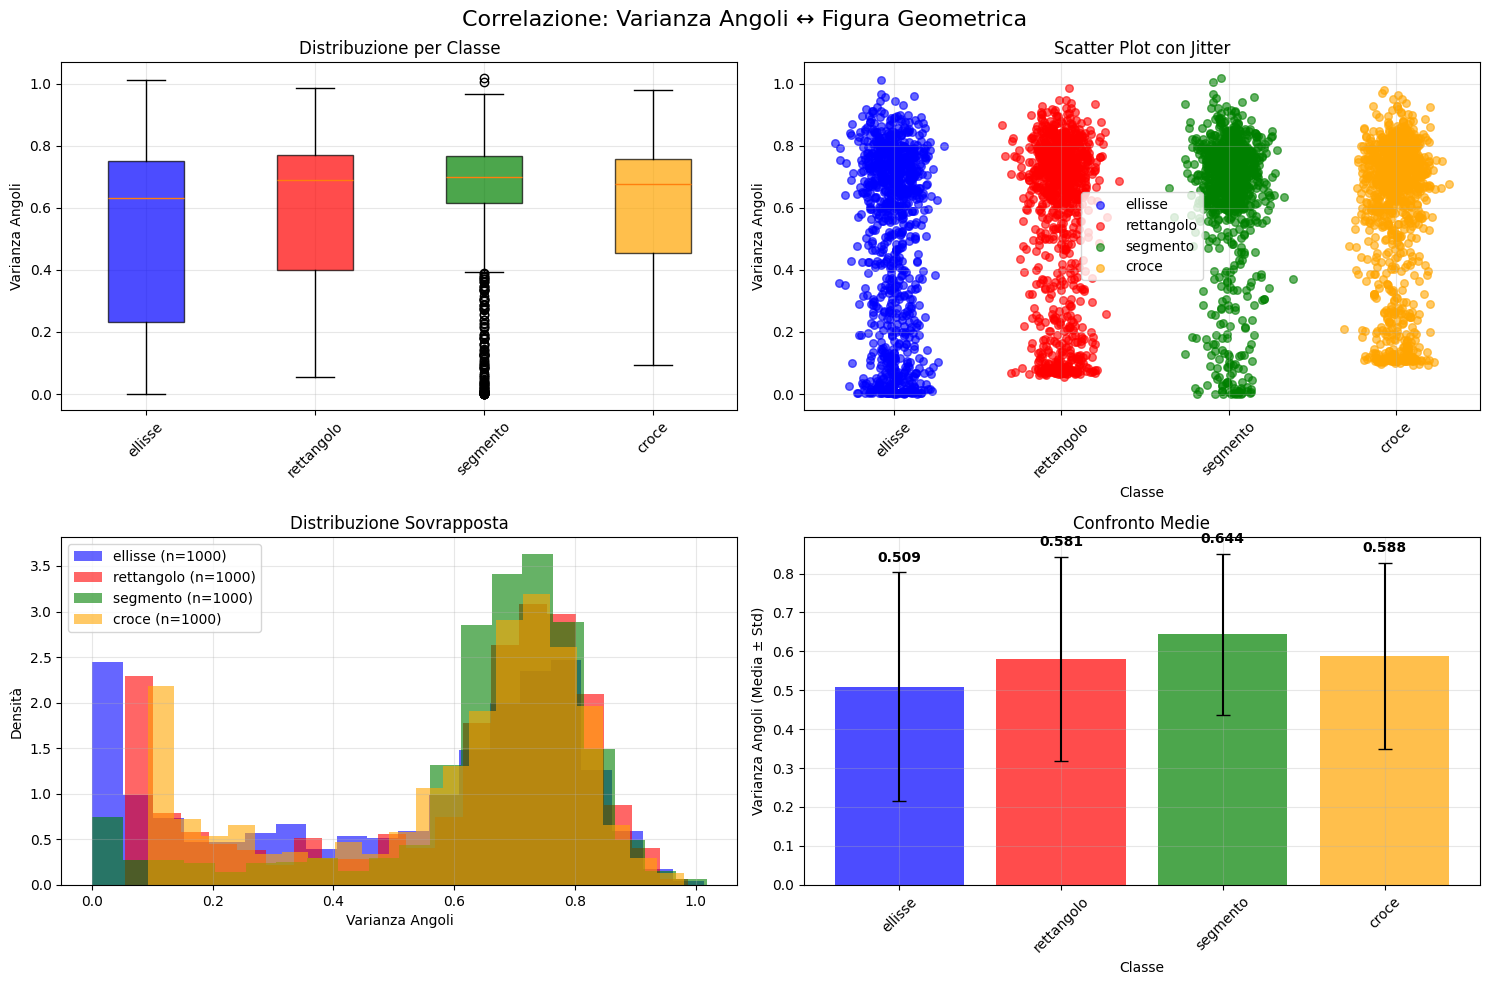

ANALISI ESPLORATIVA: VARIANZA ANGOLI PER CLASSE

Classe       N      Media      Std       
----------------------------------------
ellisse      1000   0.5091     0.2937    
rettangolo   1000   0.5811     0.2626    
segmento     1000   0.6440     0.2065    
croce        1000   0.5875     0.2389    

RANKING per varianza angoli (crescente):
  1. ellisse: 0.5091
  2. rettangolo: 0.5811
  3. croce: 0.5875
  4. segmento: 0.6440

OSSERVAZIONI:
• Rapporto varianza max/min: 1.3x
• Questa feature mostra lievi differenze tra classi
• Più regolare: ellisse | Più irregolare: segmento


{'ellisse': {'count': 1000,
  'mean': np.float64(0.5090709476601853),
  'std': np.float64(0.2936711787699684)},
 'rettangolo': {'count': 1000,
  'mean': np.float64(0.5810834422064499),
  'std': np.float64(0.26259968684014784)},
 'segmento': {'count': 1000,
  'mean': np.float64(0.6439549251292476),
  'std': np.float64(0.206532718367773)},
 'croce': {'count': 1000,
  'mean': np.float64(0.587515494202754),
  'std': np.float64(0.23889030255825255)}}

In [562]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from scipy import stats
import pandas as pd

def visualizza_correlazione_varianza_angoli(X, y, figsize=(15, 10)):
    """
    Visualizza la correlazione tra varianza degli angoli e tipo di figura geometrica.
    Versione semplificata per analisi esplorativa.
    
    Parametri:
        X (np.ndarray): Array di forme (n_samples, n_punti, 2)
        y (np.ndarray): Array di etichette (n_samples,)
        figsize (tuple): Dimensione della figura
    
    Returns:
        dict: statistiche di base per classe
    """
    
    def calcola_varianza_angoli(punti):
        """Calcola varianza degli angoli tra punti consecutivi."""
        if len(punti) < 3:
            return 0.0
            
        angoli = []
        for i in range(1, len(punti) - 1):
            # Tre punti consecutivi
            p1, p2, p3 = punti[i-1], punti[i], punti[i+1]
            
            # Vettori dal punto centrale
            v1 = p1 - p2 
            v2 = p3 - p2
            
            # Calcola angolo usando prodotto scalare
            cos_angle = np.dot(v1, v2) / (np.linalg.norm(v1) * np.linalg.norm(v2) + 1e-8)
            cos_angle = np.clip(cos_angle, -1, 1)
            angolo = np.arccos(cos_angle)
            angoli.append(angolo)
        
        return np.var(angoli) if angoli else 0.0
    
    # Calcola varianza angoli per tutti i campioni
    varianze = []
    labels_nomi = ['ellisse', 'rettangolo', 'segmento', 'croce']
    colors = ['blue', 'red', 'green', 'orange']
    
    for i in range(len(X)):
        punti = X[i]
        varianza = calcola_varianza_angoli(punti)
        varianze.append(varianza)
    
    varianze = np.array(varianze)
    
    # Organizza dati per classe
    dati_per_classe = {}
    for i, classe in enumerate(labels_nomi):
        mask = y == i
        dati_per_classe[classe] = varianze[mask]
    
    # Creazione della figura con 4 subplot essenziali
    fig, axes = plt.subplots(2, 2, figsize=figsize)
    fig.suptitle('Correlazione: Varianza Angoli ↔ Figura Geometrica', fontsize=16)
    
    # 1. Box plot per classe
    ax1 = axes[0, 0]
    varianze_per_classe = [dati_per_classe[classe] for classe in labels_nomi]
    bp = ax1.boxplot(varianze_per_classe, labels=labels_nomi, patch_artist=True)
    
    for patch, color in zip(bp['boxes'], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)
    
    ax1.set_ylabel('Varianza Angoli')
    ax1.set_title('Distribuzione per Classe')
    ax1.tick_params(axis='x', rotation=45)
    ax1.grid(True, alpha=0.3)
    
    # 2. Scatter plot: varianza vs classe
    ax2 = axes[0, 1]
    for i, classe in enumerate(labels_nomi):
        mask = y == i
        x_jitter = np.random.normal(i, 0.1, np.sum(mask))  # Aggiungi jitter per visibilità
        ax2.scatter(x_jitter, varianze[mask], 
                   c=colors[i], alpha=0.6, s=30, label=classe)
    
    ax2.set_xlabel('Classe')
    ax2.set_ylabel('Varianza Angoli')
    ax2.set_title('Scatter Plot con Jitter')
    ax2.set_xticks(range(4))
    ax2.set_xticklabels(labels_nomi, rotation=45)
    ax2.legend()
    ax2.grid(True, alpha=0.3)
    
    # 3. Istogrammi sovrapposti
    ax3 = axes[1, 0]
    for i, classe in enumerate(labels_nomi):
        data = dati_per_classe[classe]
        ax3.hist(data, bins=20, alpha=0.6, color=colors[i], 
                label=f'{classe} (n={len(data)})', density=True)
    
    ax3.set_xlabel('Varianza Angoli')
    ax3.set_ylabel('Densità')
    ax3.set_title('Distribuzione Sovrapposta')
    ax3.legend()
    ax3.grid(True, alpha=0.3)
    
    # 4. Medie per classe con barre d'errore
    ax4 = axes[1, 1]
    medie = [np.mean(dati_per_classe[classe]) for classe in labels_nomi]
    std_devs = [np.std(dati_per_classe[classe]) for classe in labels_nomi]
    
    bars = ax4.bar(range(len(labels_nomi)), medie, yerr=std_devs, 
                   color=colors, alpha=0.7, capsize=5)
    
    # Aggiungi valori sopra le barre
    for i, (media, std) in enumerate(zip(medie, std_devs)):
        ax4.text(i, media + std + 0.02, f'{media:.3f}', 
                ha='center', va='bottom', fontweight='bold')
    
    ax4.set_xlabel('Classe')
    ax4.set_ylabel('Varianza Angoli (Media ± Std)')
    ax4.set_title('Confronto Medie')
    ax4.set_xticks(range(len(labels_nomi)))
    ax4.set_xticklabels(labels_nomi, rotation=45)
    ax4.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    # ===== REPORT SEMPLIFICATO =====
    print("="*60)
    print("ANALISI ESPLORATIVA: VARIANZA ANGOLI PER CLASSE")
    print("="*60)
    
    print(f"\n{'Classe':<12} {'N':<6} {'Media':<10} {'Std':<10}")
    print("-" * 40)
    
    risultati = {}
    for classe in labels_nomi:
        data = dati_per_classe[classe]
        risultati[classe] = {
            'count': len(data),
            'mean': np.mean(data),
            'std': np.std(data),
        }
        
        print(f"{classe:<12} {len(data):<6} {np.mean(data):<10.4f} {np.std(data):<10.4f}")
    
    # Ranking semplice
    print(f"\nRANKING per varianza angoli (crescente):")
    classi_ordinate = sorted([(classe, risultati[classe]['mean']) 
                             for classe in labels_nomi], key=lambda x: x[1])
    
    for i, (classe, media) in enumerate(classi_ordinate, 1):
        print(f"  {i}. {classe}: {media:.4f}")
    
    # Osservazioni chiave
    print(f"\nOSSERVAZIONI:")
    max_var = max(risultati[classe]['mean'] for classe in labels_nomi)
    min_var = min(risultati[classe]['mean'] for classe in labels_nomi)
    rapporto = max_var / min_var if min_var > 0 else float('inf')
    
    print(f"• Rapporto varianza max/min: {rapporto:.1f}x")
    print(f"• Questa feature mostra {'chiare' if rapporto > 10 else 'moderate' if rapporto > 3 else 'lievi'} differenze tra classi")
    
    classe_min = min(labels_nomi, key=lambda x: risultati[x]['mean'])
    classe_max = max(labels_nomi, key=lambda x: risultati[x]['mean'])
    print(f"• Più regolare: {classe_min} | Più irregolare: {classe_max}")
    
    return risultati

visualizza_correlazione_varianza_angoli(X,y)

### Analisi del perimetro e area

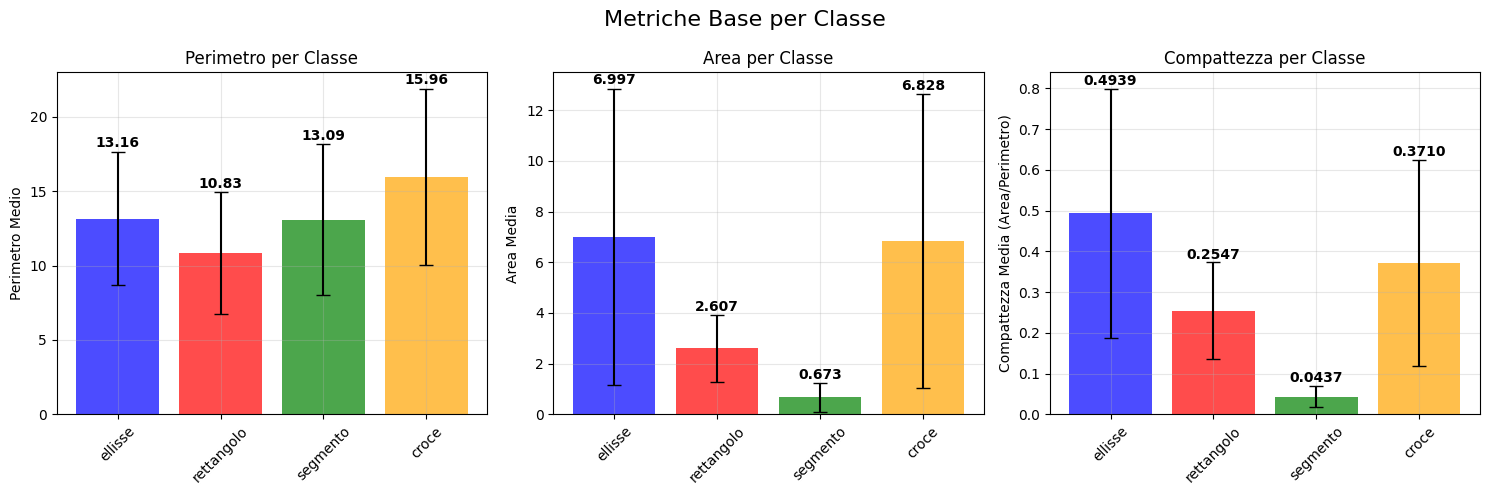

METRICHE BASE: PERIMETRO, AREA E COMPATTEZZA MEDIA

Classe       N    Perimetro    Area         Compattezza 
                  (media±std)  (media±std)  (media±std) 
----------------------------------------------------------------------
ellisse      1000 13.16±4.48   6.997±5.850   0.4939±0.3056
rettangolo   1000 10.83±4.10   2.607±1.313   0.2547±0.1183
segmento     1000 13.09±5.05   0.673±0.571   0.0437±0.0259
croce        1000 15.96±5.94   6.828±5.801   0.3710±0.2529

============================== RANKINGS ==============================

PERIMETRO (crescente):
  1. rettangolo: 10.834
  2. segmento: 13.086
  3. ellisse: 13.164
  4. croce: 15.958

AREA (crescente):
  1. segmento: 0.6734
  2. rettangolo: 2.6066
  3. croce: 6.8282
  4. ellisse: 6.9971

COMPATTEZZA (crescente):
  1. segmento: 0.04372
  2. rettangolo: 0.25468
  3. croce: 0.37097
  4. ellisse: 0.49387

========================= OSSERVAZIONI =========================

FORME 2D (area > 0.05):
  • ellisse: area=6.9971, compatt

In [563]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.spatial import ConvexHull

import matplotlib.pyplot as plt
import numpy as np
from scipy.spatial import ConvexHull

def calcola_metriche_base_forme(X, y, visualizza=True):
    """
    Calcola perimetro, area e compattezza per ogni forma e mostra le medie per classe.
    
    Parametri:
        X (np.ndarray): Array di forme (n_samples, n_punti, 2)
        y (np.ndarray): Array di etichette (n_samples,)
        visualizza (bool): Se True mostra i grafici
    
    Returns:
        tuple: (features_array, stats_per_classe)
    """
    
    def calcola_perimetro(punti):
        """Calcola il perimetro della forma."""
        if len(punti) < 2:
            return 0.0
        
        perimetro = 0.0
        for i in range(len(punti)):
            p1 = punti[i]
            p2 = punti[(i + 1) % len(punti)]  # Connetti ultimo al primo
            perimetro += np.linalg.norm(p2 - p1)
        
        return perimetro
    
    def calcola_area(punti):
        """Calcola l'area usando il convex hull."""
        if len(punti) < 3:
            return 0.0
        
        try:
            hull = ConvexHull(punti)
            return hull.volume  # In 2D, volume = area
        except:
            return 0.0
    
    # Calcola metriche per tutti i campioni
    n_samples = len(X)
    perimetri = np.zeros(n_samples)
    aree = np.zeros(n_samples)
    compattezza = np.zeros(n_samples)
    
    for i in range(n_samples):
        punti = X[i]
        
        # Calcola metriche base
        perimetro = calcola_perimetro(punti)
        area = calcola_area(punti)
        
        perimetri[i] = perimetro
        aree[i] = area
        
        # Compattezza = area / perimetro (normalizzata)
        if perimetro > 0:
            compattezza[i] = area / perimetro
        else:
            compattezza[i] = 0.0
    
    # Crea array delle feature
    features = np.column_stack([perimetri, aree, compattezza])
    
    # Calcola statistiche per classe
    labels_nomi = ['ellisse', 'rettangolo', 'segmento', 'croce']
    colors = ['blue', 'red', 'green', 'orange']
    
    stats_per_classe = {}
    
    for i, classe in enumerate(labels_nomi):
        mask = y == i
        stats_per_classe[classe] = {
            'perimetro_medio': np.mean(perimetri[mask]),
            'perimetro_std': np.std(perimetri[mask]),
            'area_media': np.mean(aree[mask]),
            'area_std': np.std(aree[mask]),
            'compattezza_media': np.mean(compattezza[mask]),
            'compattezza_std': np.std(compattezza[mask]),
            'n_campioni': np.sum(mask)
        }
    
    if visualizza:
        # Grafico con 3 subplot
        fig, axes = plt.subplots(1, 3, figsize=(15, 5))
        fig.suptitle('Metriche Base per Classe', fontsize=16)
        
        # 1. Perimetro medio
        ax1 = axes[0]
        perimetri_medi = [stats_per_classe[classe]['perimetro_medio'] for classe in labels_nomi]
        perimetri_std = [stats_per_classe[classe]['perimetro_std'] for classe in labels_nomi]
        
        bars1 = ax1.bar(range(len(labels_nomi)), perimetri_medi, yerr=perimetri_std,
                       color=colors, alpha=0.7, capsize=5)
        
        for i, (media, std) in enumerate(zip(perimetri_medi, perimetri_std)):
            ax1.text(i, media + std + 0.1, f'{media:.2f}', 
                    ha='center', va='bottom', fontweight='bold')
        
        ax1.set_ylabel('Perimetro Medio')
        ax1.set_title('Perimetro per Classe')
        ax1.set_xticks(range(len(labels_nomi)))
        ax1.set_xticklabels(labels_nomi, rotation=45)
        ax1.grid(True, alpha=0.3)
        
        # 2. Area media
        ax2 = axes[1]
        aree_medie = [stats_per_classe[classe]['area_media'] for classe in labels_nomi]
        aree_std = [stats_per_classe[classe]['area_std'] for classe in labels_nomi]
        
        bars2 = ax2.bar(range(len(labels_nomi)), aree_medie, yerr=aree_std,
                       color=colors, alpha=0.7, capsize=5)
        
        for i, (media, std) in enumerate(zip(aree_medie, aree_std)):
            ax2.text(i, media + std + 0.05, f'{media:.3f}', 
                    ha='center', va='bottom', fontweight='bold')
        
        ax2.set_ylabel('Area Media')
        ax2.set_title('Area per Classe')
        ax2.set_xticks(range(len(labels_nomi)))
        ax2.set_xticklabels(labels_nomi, rotation=45)
        ax2.grid(True, alpha=0.3)
        
        # 3. Compattezza media
        ax3 = axes[2]
        compattezza_medie = [stats_per_classe[classe]['compattezza_media'] for classe in labels_nomi]
        compattezza_std = [stats_per_classe[classe]['compattezza_std'] for classe in labels_nomi]
        
        bars3 = ax3.bar(range(len(labels_nomi)), compattezza_medie, yerr=compattezza_std,
                       color=colors, alpha=0.7, capsize=5)
        
        for i, (media, std) in enumerate(zip(compattezza_medie, compattezza_std)):
            ax3.text(i, media + std + 0.002, f'{media:.4f}', 
                    ha='center', va='bottom', fontweight='bold')
        
        ax3.set_ylabel('Compattezza Media (Area/Perimetro)')
        ax3.set_title('Compattezza per Classe')
        ax3.set_xticks(range(len(labels_nomi)))
        ax3.set_xticklabels(labels_nomi, rotation=45)
        ax3.grid(True, alpha=0.3)
        
        plt.tight_layout()
        plt.show()
    
    # Report tabellare
    print("="*70)
    print("METRICHE BASE: PERIMETRO, AREA E COMPATTEZZA MEDIA")
    print("="*70)
    
    print(f"\n{'Classe':<12} {'N':<4} {'Perimetro':<12} {'Area':<12} {'Compattezza':<12}")
    print(f"{'':12} {'':4} {'(media±std)':<12} {'(media±std)':<12} {'(media±std)':<12}")
    print("-"*70)
    
    for classe in labels_nomi:
        stats = stats_per_classe[classe]
        print(f"{classe:<12} {stats['n_campioni']:<4} "
              f"{stats['perimetro_medio']:.2f}±{stats['perimetro_std']:.2f}   "
              f"{stats['area_media']:.3f}±{stats['area_std']:.3f}   "
              f"{stats['compattezza_media']:.4f}±{stats['compattezza_std']:.4f}")
    
    # Ranking e osservazioni
    print(f"\n{'='*30} RANKINGS {'='*30}")
    
    print(f"\nPERIMETRO (crescente):")
    ranking_perimetro = sorted([(classe, stats_per_classe[classe]['perimetro_medio']) 
                               for classe in labels_nomi], key=lambda x: x[1])
    for i, (classe, valore) in enumerate(ranking_perimetro, 1):
        print(f"  {i}. {classe}: {valore:.3f}")
    
    print(f"\nAREA (crescente):")
    ranking_area = sorted([(classe, stats_per_classe[classe]['area_media']) 
                          for classe in labels_nomi], key=lambda x: x[1])
    for i, (classe, valore) in enumerate(ranking_area, 1):
        print(f"  {i}. {classe}: {valore:.4f}")
    
    print(f"\nCOMPATTEZZA (crescente):")
    ranking_compattezza = sorted([(classe, stats_per_classe[classe]['compattezza_media']) 
                                 for classe in labels_nomi], key=lambda x: x[1])
    for i, (classe, valore) in enumerate(ranking_compattezza, 1):
        print(f"  {i}. {classe}: {valore:.5f}")
    
    # Osservazioni chiave
    print(f"\n{'='*25} OSSERVAZIONI {'='*25}")
    
    # Separazione forme 2D vs 1D
    forme_2d = []
    forme_1d = []
    
    for classe in labels_nomi:
        area_media = stats_per_classe[classe]['area_media']
        if area_media > 0.05:  # Soglia per area significativa
            forme_2d.append((classe, area_media))
        else:
            forme_1d.append((classe, area_media))
    
    print(f"\nFORME 2D (area > 0.05):")
    for classe, area in forme_2d:
        compattezza = stats_per_classe[classe]['compattezza_media']
        print(f"  • {classe}: area={area:.4f}, compattezza={compattezza:.5f}")
    
    print(f"\nFORME 1D (area ≤ 0.05):")
    for classe, area in forme_1d:
        compattezza = stats_per_classe[classe]['compattezza_media']
        print(f"  • {classe}: area={area:.4f}, compattezza={compattezza:.5f}")
    
    print(f"\nPOTERE DISCRIMINANTE:")
    print(f"  • AREA: Eccellente per separare forme 2D vs 1D")
    print(f"  • COMPATTEZZA: Ottima per distinguere forme 'rotonde' vs 'spigolose'")
    print(f"  • PERIMETRO: Buono per distinguere forme di diverse dimensioni")
    


calcola_metriche_base_forme(X,y)

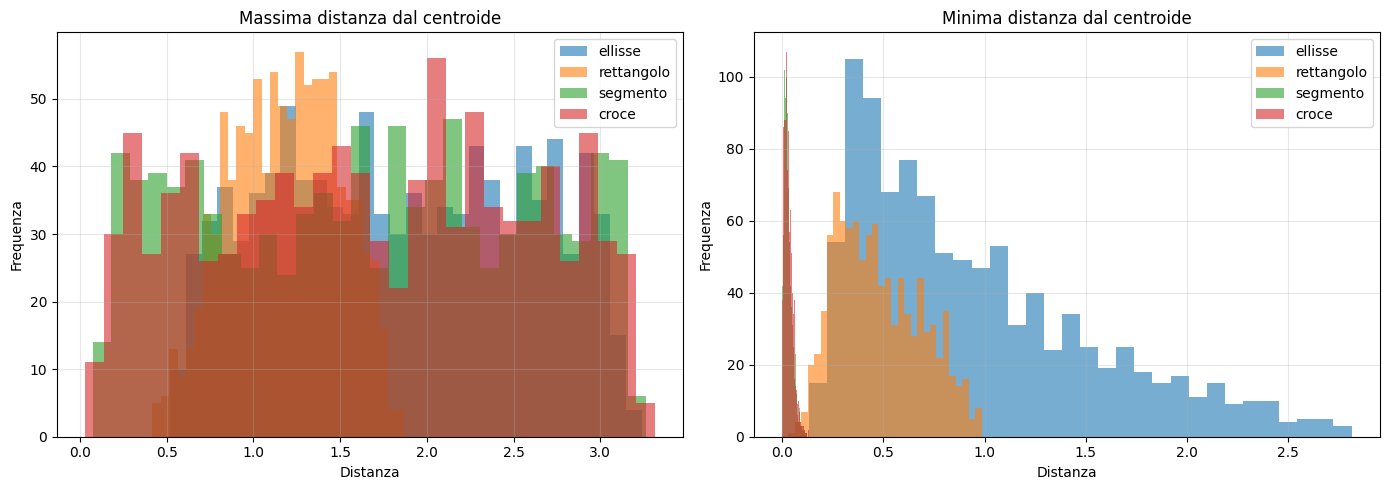

In [564]:
import numpy as np

import matplotlib.pyplot as plt

def plot_max_min_distance_distribution(X, y, labels=labels):
    """
    Visualizza la distribuzione della massima e minima distanza dal centroide
    per ciascun tipo di figura geometrica.

    Args:
        X (np.ndarray): array di forme (n_samples, n_punti, 2)
        y (np.ndarray): array di etichette (n_samples,)
        labels (list): nomi delle classi
    """
    max_dists = []
    min_dists = []
    for punti in X:
        centroide = np.mean(punti, axis=0)
        dists = np.linalg.norm(punti - centroide, axis=1)
        max_dists.append(np.max(dists))
        min_dists.append(np.min(dists))
    max_dists = np.array(max_dists)
    min_dists = np.array(min_dists)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    for idx, (dist, title) in enumerate(zip([max_dists, min_dists], ['Massima distanza dal centroide', 'Minima distanza dal centroide'])):
        for i, label in enumerate(labels):
            axes[idx].hist(dist[y == i], bins=30, alpha=0.6, label=label)
        axes[idx].set_title(title)
        axes[idx].set_xlabel('Distanza')
        axes[idx].set_ylabel('Frequenza')
        axes[idx].legend()
        axes[idx].grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

# Esempio d'uso:
plot_max_min_distance_distribution(X, y)

In [565]:
def get_vector_representation(X):
    """
    Converte una sequenza di array di punti 2D (shape: N, n_punti, 2)
    in una rappresentazione vettoriale piatta (shape: N, n_punti*2).

    Ogni forma viene "appiattita" in un unico vettore concatenando tutte le coordinate x e y.

    Args:
        X (np.ndarray): array di forme, ciascuna rappresentata da una sequenza di punti 2D.

    Returns:
        np.ndarray: array 2D dove ogni riga è la rappresentazione vettoriale di una forma.
    """
    return np.array([list(x.flatten()) for x in X])

## Feature definition

In [ ]:
def calcola_distanze_punti_opposti(X):
    """
    Calcola la distanza tra ogni punto e il suo punto opposto nella sequenza.
    
    Args:
        X (np.ndarray): Array di forme (n_samples, n_punti, 2)
    
    Returns:
        np.ndarray: Array di distanze (n_samples, n_punti)
                   dove [i,j] è la distanza tra il punto j e il suo opposto nella forma i
    """
    import numpy as np
    
    n_samples, n_punti, _ = X.shape
    distanze_opposte = np.zeros((n_samples, n_punti))
    
    for i in range(n_samples):
        punti = X[i]  # Shape: (n_punti, 2)
        
        for j in range(n_punti):
            # Calcola l'indice del punto opposto
            indice_opposto = (j + n_punti // 2) % n_punti
            
            # Calcola distanza euclidea tra punto j e il suo opposto
            punto_j = punti[j]
            punto_opposto = punti[indice_opposto]
            
            distanza = np.sqrt(np.sum((punto_j - punto_opposto)**2))
            distanze_opposte[i, j] = distanza
    
    return distanze_opposte

def ottieni_features(X):
    from scipy.spatial import ConvexHull  # Aggiungi questo import
    
    n_samples, n_punti, n_coords = X.shape    
    
    # Inizializza le feature arrays
    angoli = np.zeros((n_samples, n_punti))   
    distanze = np.zeros((n_samples, n_punti))
    perimetri = np.zeros((n_samples, 1))
    distanza_estremi = np.zeros((n_samples, 1))
    varianza_distanze = np.zeros((n_samples, 1))
    angoli_curvatura = np.zeros((n_samples, n_punti))
    curvatura_locale = np.zeros((n_samples, n_punti))
    variazione_curvatura = np.zeros((n_samples, 1))
    aree = np.zeros((n_samples, 1))          
    compattezza = np.zeros((n_samples, 1))   
     
    for i in range(n_samples):
        coords = X[i]
        centro = np.mean(coords, axis=0)
        vettori = coords - centro
        
        # === COEFFICIENTI ANGOLARI ===
        for j in range(n_punti):
            punto_corrente = coords[j]
            delta_x = punto_corrente[0] - centro[0]
            delta_y = punto_corrente[1] - centro[1]
            
            if abs(delta_x) > 1e-10:
                angoli[i, j] = delta_y / delta_x
            else:
                angoli[i, j] = np.inf if delta_y > 0 else -np.inf
        
        # === DISTANZE DAL CENTRO ===
        distanze[i] = np.sqrt(np.sum(vettori**2, axis=1)) 
    min_distanza = np.zeros((n_samples,1))
    for i in range(n_samples):
        min_distanza[i] = np.min(distanze[i])


        # === DISTANZA TRA ESTREMI ===
        distanza_estremi[i] = np.sqrt(np.sum((coords[0] - coords[-1])**2))
        
        # === PERIMETRO ===
        distanze_segmenti = np.zeros(n_punti)
        for j in range(n_punti):
            punto_corrente = coords[j]
            punto_successivo = coords[(j + 1) % n_punti]
            distanze_segmenti[j] = np.sqrt(np.sum((punto_successivo - punto_corrente)**2))
        perimetri[i] = np.sum(distanze_segmenti)
        
        # === AREA (NUOVO) ===
        try:
            if len(coords) >= 3:
                hull = ConvexHull(coords)
                aree[i] = hull.volume  # In 2D, volume = area
            else:
                aree[i] = 0.0
        except:
            aree[i] = 0.0
        
        # === COMPATTEZZA (NUOVO) ===
        if perimetri[i] > 0:
            compattezza[i] = aree[i] / perimetri[i]
        else:
            compattezza[i] = 0.0
        
        # === VARIANZA DISTANZE ===
        varianza_distanze[i] = np.var(distanze[i])
        
        # === CURVATURA E ANGOLI ===
        for j in range(n_punti):
            p_prev = coords[(j - 1) % n_punti]
            p_curr = coords[j]
            p_next = coords[(j + 1) % n_punti]
            
            v1 = p_curr - p_prev
            v2 = p_next - p_curr
            
            cross_product = v1[0] * v2[1] - v1[1] * v2[0]
            norm_v1 = np.linalg.norm(v1)
            norm_v2 = np.linalg.norm(v2)
            
            if norm_v1 > 1e-10 and norm_v2 > 1e-10:
                sin_angolo = cross_product / (norm_v1 * norm_v2)
                curvatura_locale[i, j] = abs(sin_angolo) / ((norm_v1 + norm_v2) / 2)
                
                dot_product = np.dot(v1, v2)
                cos_angolo = dot_product / (norm_v1 * norm_v2)
                angoli_curvatura[i, j] = np.arccos(np.clip(cos_angolo, -1, 1))
        
        # === VARIAZIONE CURVATURA ===
        variazione_curvatura[i] = np.var(curvatura_locale[i])
    
    # === COORDINATE RELATIVE AL CENTROIDE ===
    X_relative = np.zeros_like(X)
    for i in range(n_samples):
        centroide = np.mean(X[i], axis=0)  
        X_relative[i] = X[i] - centroide
    
    X_relative_appiattito = X_relative.reshape(n_samples, -1)
    centroide = np.mean(X,axis=1)
    varianza_distanze_espanse = np.tile(varianza_distanze, (1, n_punti))
    
    prova = get_vector_representation(X)
    
    # === CONCATENAZIONE FINALE ===
    df =  pd.DataFrame(np.concatenate([
        centroide, 
        X_relative_appiattito,
        distanza_estremi,
        min_distanza,
        distanze,
        #varianza_distanze,
        #perimetri,
        #aree,          
        #compattezza,   
        #variazione_curvatura,
        calcola_distanze_punti_opposti(X)
    ], axis=1))
    df.columns = [
        'centroide_x', 'centroide_y',
        *[f'coord_rel_x_{i}' for i in range(100)],
        *[f'coord_rel_y_{i}' for i in range(100)],
        'distanza_estremi',
        'min_distanza',
        *[f'distanza_centro_{i}' for i in range(100)],
        'varianza_distanze',
        'perimetro',
        'area',
        'compattezza',
        'variazione_curvatura',
        *[f'distanza_matrice_{i}' for i in range(100)]  
    ]
    return df

In [567]:
X, y = genera_campioni(n_shapes=1000, n_punti=100, rumore_std_bound=1)
esporta_dataset("figureGeometriche.csv",X,y)

In [568]:
print("Shape di X:", X.shape)
print("Shape di y:", y.shape)

Shape di X: (4000, 100, 2)
Shape di y: (4000,)


## Feature Selection

In [569]:

X_f = ottieni_features(X)

def visualizza_importanza_features_con_nomi(X_features, y, top_n, figsize=(14, 8)):
    """
    Visualizza l'importanza delle feature con i nomi descrittivi
    """
    from sklearn.ensemble import RandomForestClassifier
    import matplotlib.pyplot as plt
    import numpy as np
    
    # Crea mappatura
    feature_map = X_features.columns
    feature_map = {i: name for i, name in enumerate(feature_map)}
    
    # Addestra Random Forest
    rf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
    rf.fit(X_features, y)
    
    # Ottieni importanze
    importances = rf.feature_importances_
    indices = np.argsort(importances)[::-1]
    # Crea il grafico
    plt.figure(figsize=figsize)
    
    # Top N feature
    top_indices = indices[:top_n]
    top_importances = importances[top_indices]
    
    # Nomi delle feature
    feature_names = [feature_map.get(idx, f"Feature_{idx}") for idx in top_indices]
    
    # Grafico a barre orizzontali
    bars = plt.barh(range(top_n), top_importances, color='skyblue', edgecolor='navy', alpha=0.7)
    
    # Personalizza il grafico
    plt.yticks(range(top_n), feature_names)
    plt.xlabel('Importanza', fontsize=12)
    plt.title(f'Top {top_n} Feature più Importanti (Random Forest)', fontsize=14, fontweight='bold')
    plt.gca().invert_yaxis()
    
    # Aggiungi valori sulle barre
    for i, (bar, importance) in enumerate(zip(bars, top_importances)):
        plt.text(importance + 0.001, bar.get_y() + bar.get_height()/2, 
                f'{importance:.4f}', va='center', ha='left', fontsize=9)
    
    # Media
    media_importanza = np.mean(importances)
    plt.axvline(media_importanza, color='red', linestyle='--', alpha=0.8, 
                label=f'Media: {media_importanza:.4f}')
    plt.legend()
    
    plt.tight_layout()
    plt.grid(axis='x', alpha=0.3)
    plt.show()
    

    return importances, indices[:top_n], feature_map

#importances, top_features, mapping = visualizza_importanza_features_con_nomi(X_f, y, top_n=20)
#X_f = X_f.iloc[:, top_features]

In [570]:
print("Shape di X_f:", X_f.shape)
print("Shape di y:", y.shape)

Shape di X_f: (4000, 409)
Shape di y: (4000,)


## Feature Exctraction

In [571]:
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
# Numero di componenti principali da estrarre (eigenfaces)
n_components = 100

# Crea e adatta la PCA sui dati di training
# - n_components: numero di componenti principali da mantenere
# - svd_solver='randomized': metodo più veloce per dataset grandi
# - whiten=True: normalizza le componenti principali

X_train, X_test, y_train, y_test = train_test_split(X_f, y, test_size=0.3, random_state=42, stratify=y)
pca = PCA(n_components=n_components, svd_solver='randomized', whiten=True).fit(X_train)

# Estrae le componenti principali (eigenfaces) e le rimodella nella forma delle immagini originali
X_train_pca = pca.transform(X_train)
X_test_pca = pca.transform(X_test)

/Users/simonepellegrini/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: divide by zero encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/simonepellegrini/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: overflow encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/simonepellegrini/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: invalid value encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/simonepellegrini/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:336: RuntimeWarning: divide by zero encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/Users/simonepellegrini/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:336: RuntimeWarning: overflow encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/Users/simonepellegrini/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:336: RuntimeWarning: inval

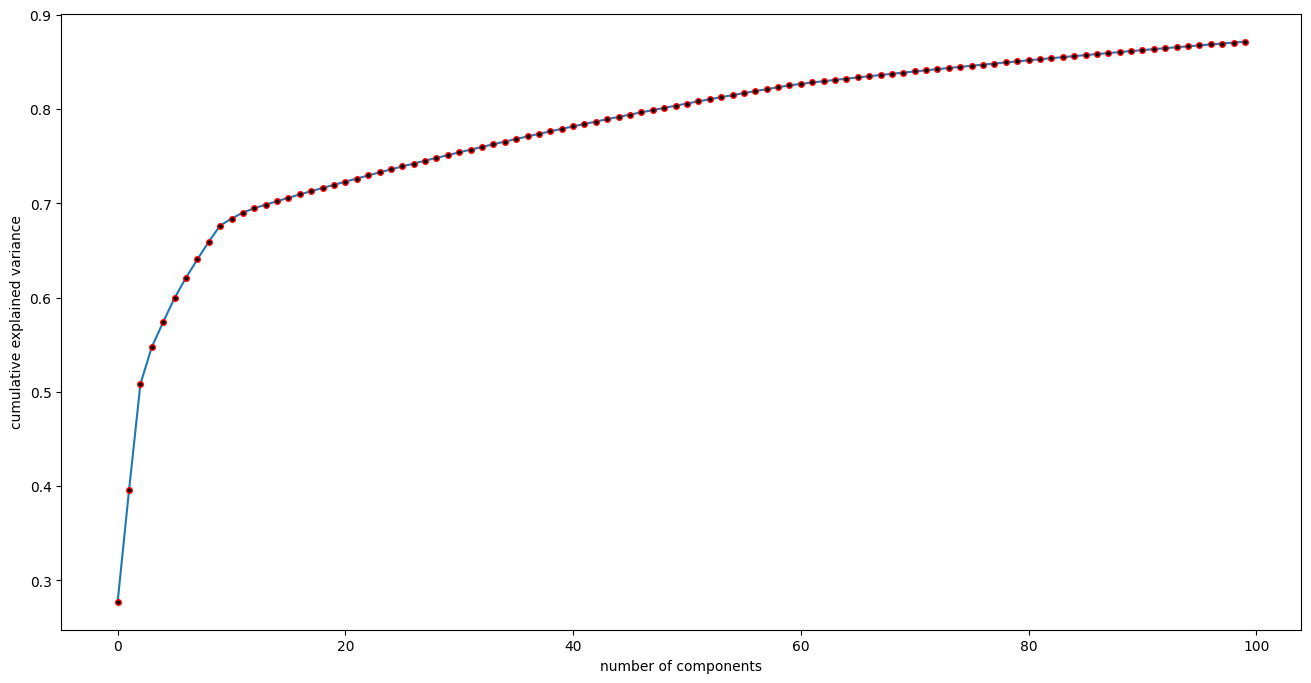

In [572]:
plt.figure(figsize=(16,8))
plt.plot(np.cumsum(pca.explained_variance_ratio_), marker='o', markersize=4, markerfacecolor="black", markeredgecolor="red")
plt.xlabel('number of components')
plt.ylabel('cumulative explained variance')
plt.show()

### Model selection

# SVC

In [573]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
from sklearn.metrics import f1_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV


param_grid = {'C': [77, 77.5, 78], 'gamma': [0.0017, 0.0018, 0.0019] }

clf = GridSearchCV(SVC(kernel='rbf'), param_grid, cv=7, scoring='accuracy')
sc = StandardScaler()
sc.fit(X_train)
X_train_std = sc.transform(X_train)
X_test_std = sc.transform(X_test)
clf = SVC()
X_train_pca = pca.transform(X_train_std)
X_test_pca = pca.transform(X_test_std)
X_train_pca
clf.fit(X_train_pca, y_train)
y_pred = clf.predict(X_train_pca)
acc = accuracy_score(y_train, y_pred)
print(f"Accuracy sul training set: {acc:.4f}")
y_pred = clf.predict(X_test_pca)
acc = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test,y_pred,average="macro")
print(f"Accuracy sul test set: {acc:.4f}")
print(f"F1-score sul test set: {f1:.4f}")

/Users/simonepellegrini/Library/Python/3.9/lib/python/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(
/Users/simonepellegrini/Library/Python/3.9/lib/python/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: divide by zero encountered in matmul
  X_transformed = X @ self.components_.T
/Users/simonepellegrini/Library/Python/3.9/lib/python/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: overflow encountered in matmul
  X_transformed = X @ self.components_.T
/Users/simonepellegrini/Library/Python/3.9/lib/python/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: invalid value encountered in matmul
  X_transformed = X @ self.components_.T
/Users/simonepellegrini/Library/Python/3.9/lib/python/site-packages/sklearn/decomposition/_base.py:155: RuntimeWarning: divide by zero encountered in matmul
  X_transformed -= xp.reshape(self.mean_, (1, -1)

Accuracy sul training set: 0.9575
Accuracy sul test set: 0.8017
F1-score sul test set: 0.8044


# Random forest

In [574]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
import numpy as np

# Classificatore e PCA
clf = RandomForestClassifier(n_estimators=100, random_state=42)
# Training
clf.fit(X_train_pca, y_train)

# Predizioni
y_pred_train = clf.predict(X_train_pca)
y_pred_test = clf.predict(X_test_pca)

# Metriche generali
acc_train = accuracy_score(y_train, y_pred_train)
acc_test = accuracy_score(y_test, y_pred_test)
f1_test = f1_score(y_test, y_pred_test, average="macro")

print(f"Accuracy sul training set: {acc_train:.4f}")
print(f"Accuracy sul test set: {acc_test:.4f}")
print(f"F1-score sul test set: {f1_test:.4f}")

# ===== PRECISIONE E RECALL PER OGNI CLASSE =====

# Nomi delle classi
labels_nomi = ['ellisse', 'rettangolo', 'segmento', 'croce']

# Calcola precisione e recall per ogni classe
precision_per_classe = precision_score(y_test, y_pred_test, average=None)
recall_per_classe = recall_score(y_test, y_pred_test, average=None)
f1_per_classe = f1_score(y_test, y_pred_test, average=None)

print("\n" + "="*50)
print("METRICHE PER CLASSE:")
print("="*50)

for i, nome_classe in enumerate(labels_nomi):
    print(f"{nome_classe.capitalize():<12} | "
          f"Precision: {precision_per_classe[i]:.4f} | "
          f"Recall: {recall_per_classe[i]:.4f} | "
          f"F1-Score: {f1_per_classe[i]:.4f}")

# ===== METRICHE AGGREGATE =====
print("\n" + "="*50)
print("METRICHE AGGREGATE:")
print("="*50)

# Precisione media (macro e weighted)
precision_macro = precision_score(y_test, y_pred_test, average='macro')
precision_weighted = precision_score(y_test, y_pred_test, average='weighted')

# Recall media (macro e weighted)
recall_macro = recall_score(y_test, y_pred_test, average='macro')
recall_weighted = recall_score(y_test, y_pred_test, average='weighted')

# F1-Score medio (macro e weighted)
f1_macro = f1_score(y_test, y_pred_test, average='macro')
f1_weighted = f1_score(y_test, y_pred_test, average='weighted')

print(f"Precision (macro avg):    {precision_macro:.4f}")
print(f"Precision (weighted avg): {precision_weighted:.4f}")
print(f"Recall (macro avg):       {recall_macro:.4f}")
print(f"Recall (weighted avg):    {recall_weighted:.4f}")
print(f"F1-Score (macro avg):     {f1_macro:.4f}")
print(f"F1-Score (weighted avg):  {f1_weighted:.4f}")

# ===== CLASSIFICATION REPORT =====
print("\n" + "="*50)
print("CLASSIFICATION REPORT COMPLETO:")
print("="*50)
print(classification_report(y_test, y_pred_test, 
                          target_names=labels_nomi, 
                          digits=4))

# ===== CONFUSION MATRIX =====
print("\n" + "="*50)
print("MATRICE DI CONFUSIONE:")
print("="*50)
cm = confusion_matrix(y_test, y_pred_test)
print("     ", end="")
for nome in labels_nomi:
    print(f"{nome[:8]:>8}", end="")
print()

for i, nome_vera in enumerate(labels_nomi):
    print(f"{nome_vera[:8]:<8}", end="")
    for j in range(len(labels_nomi)):
        print(f"{cm[i, j]:>8}", end="")
    print()

# ===== ANALISI DEGLI ERRORI =====
print("\n" + "="*50)
print("ANALISI ERRORI PIÙ COMUNI:")
print("="*50)

# Trova le confusioni più comuni (escludendo la diagonal)
errori_comuni = []
for i in range(len(labels_nomi)):
    for j in range(len(labels_nomi)):
        if i != j and cm[i, j] > 0:
            errori_comuni.append((cm[i, j], labels_nomi[i], labels_nomi[j]))

# Ordina per numero di errori
errori_comuni.sort(reverse=True, key=lambda x: x[0])

print("Confusioni più frequenti:")
for count, vera, predetta in errori_comuni[:5]:  # Top 5 errori
    percentuale = (count / np.sum(cm[labels_nomi.index(vera)])) * 100
    print(f"  {vera} → {predetta}: {count} errori ({percentuale:.1f}%)")

# ===== PERFORMANCE PER CLASSE =====
print("\n" + "="*50)
print("SUPPORTO PER CLASSE (numero di campioni):")
print("="*50)
unique, counts = np.unique(y_test, return_counts=True)
for classe, count in zip(unique, counts):
    print(f"{labels_nomi[classe]}: {count} campioni")

Accuracy sul training set: 1.0000
Accuracy sul test set: 0.8875
F1-score sul test set: 0.8883

METRICHE PER CLASSE:
Ellisse      | Precision: 0.9135 | Recall: 0.8100 | F1-Score: 0.8587
Rettangolo   | Precision: 0.7855 | Recall: 0.9033 | F1-Score: 0.8403
Segmento     | Precision: 0.9750 | Recall: 0.9100 | F1-Score: 0.9414
Croce        | Precision: 0.8997 | Recall: 0.9267 | F1-Score: 0.9130

METRICHE AGGREGATE:
Precision (macro avg):    0.8934
Precision (weighted avg): 0.8934
Recall (macro avg):       0.8875
Recall (weighted avg):    0.8875
F1-Score (macro avg):     0.8883
F1-Score (weighted avg):  0.8883

CLASSIFICATION REPORT COMPLETO:
              precision    recall  f1-score   support

     ellisse     0.9135    0.8100    0.8587       300
  rettangolo     0.7855    0.9033    0.8403       300
    segmento     0.9750    0.9100    0.9414       300
       croce     0.8997    0.9267    0.9130       300

    accuracy                         0.8875      1200
   macro avg     0.8934    0.8

-reg_log (softmax)
-svm con (kernel trick)
-random_forest
-k_nn
-reti neurali (?)
-classificatori bayesiani


-feature extraction PCA
-feature selection con alberi di decisione
-regressione lineare(?)
-F1 Score,accuracy, recall,precision,AUC 
-normalizzazione
-undersampling, oversampling con smote
-training set, validation set e test set, cross validation

